# 01. Fontes e qualidade dos dados

Antes de comparar regiões, é preciso saber o que cada base mede, quem ela cobre e onde ela falha. Este caderno apresenta as cinco fontes usadas, verifica a cobertura ao longo do tempo e mede quanta informação está faltando em cada variável. As decisões tomadas aqui, como quais anos usar, valem para todos os outros cadernos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g
from mama.config import FONTE_RHC, FONTE_PAINEL
from mama.analises import base

pd.set_option("display.max_columns", 20)

## As fontes

| Fonte | Quem está na base | Período usado | Para que serve aqui |
|---|---|---|---|
| RHC (INCA) | Mulheres atendidas em hospitais que mantêm registro hospitalar de câncer, públicos ou privados | 2013 a 2022 | Perfil sociodemográfico, estádio, tipo histológico, tempos e local de tratamento |
| Painel de Oncologia (DATASUS) | Mulheres diagnosticadas ou tratadas pelo SUS | 2013 a 2024 | Tempo até o tratamento e deslocamento no SUS |
| SISCAN (DATASUS) | Mamografias e laudos de histopatologia de mama feitos no SUS | Mamografias de 2019 e 2024; laudos de 2014 a 2024 | Rastreamento, resultado dos exames e características do tumor |
| APAC de quimioterapia (DATASUS) | Mulheres em quimioterapia ou hormonioterapia pelo SUS | 2023 e 2024 | Proxy de subtipo molecular e deslocamento por tipo de tratamento |
| APAC de radioterapia (DATASUS) | Mulheres em radioterapia pelo SUS | 2023 e 2024 | Espera e deslocamento para a radioterapia |
| CNES (DATASUS) | Todos os estabelecimentos de saúde do país, com seus equipamentos e habilitações | Setembro de 2025 e anos anteriores | Equipamentos e serviços disponíveis |
| SIM (DATASUS) | Todos os óbitos com causa básica câncer de mama | 2013 a 2024 | Mortalidade |
| População (IBGE/DATASUS) | Estimativas de mulheres por idade e município | 2013 a 2025 | Denominador das taxas |

Nenhuma dessas bases identifica a paciente pelo nome ou documento, e elas não podem ser cruzadas entre si. Por isso cada indicador vem de uma única fonte, e números de fontes diferentes não devem ser somados.

## Quantos casos há em cada base

O RHC é organizado pelo ano da primeira consulta no hospital. O Painel, pelo ano do diagnóstico. A tabela abaixo mostra o total de casos de câncer de mama em mulheres por ano em cada uma.

In [2]:
rhc_todos = base.carregar("rhc")
painel_todos = base.carregar("painel")

contagem = pd.DataFrame({
    "RHC (todos os casos)": rhc_todos.groupby("ano_consulta").size(),
    "RHC (casos analíticos)": rhc_todos[rhc_todos.caso_analitico].groupby("ano_consulta").size(),
    "Painel (C50, SUS)": painel_todos[painel_todos.cid == "C50"].groupby("ano_diagnostico").size(),
})
contagem.index.name = "ano"
contagem

,RHC (todos os casos),RHC (casos analíticos),"Painel (C50, SUS)"
ano,,,
2013,44730.0,31945.0,41091
2014,45228.0,33552.0,36688
2015,44969.0,33635.0,36095
2016,46985.0,35161.0,37420
2017,48161.0,35701.0,38504
2018,49434.0,36670.0,43948
2019,52107.0,38626.0,52120
2020,45824.0,34361.0,48277
2021,48198.0,36876.0,55404


Dois anos se destacam. Em 2020 há uma queda nas duas bases, efeito da pandemia de COVID-19, que interrompeu consultas e exames. Em 2023 o RHC tem menos da metade dos casos dos anos anteriores: os hospitais enviam seus registros com dois a três anos de atraso, então esse ano ainda está incompleto. No Painel, os anos de 2025 e 2026 também estão incompletos, porque os tratamentos dos diagnósticos recentes ainda estão sendo registrados.

Por isso, todos os cadernos usam o RHC de 2013 a 2022 e o Painel de 2013 a 2024. Esses recortes estão definidos em um único lugar, o arquivo `src/mama/config.py`.

## Cobertura do RHC por estado

O RHC depende de cada hospital enviar seus dados. Quando um hospital grande deixa de enviar, o estado inteiro parece ter menos casos. Para enxergar isso, o gráfico abaixo compara cada ano com a média do próprio estado. O valor 100 significa um ano típico; valores muito abaixo de 100 indicam que faltam hospitais naquele ano.

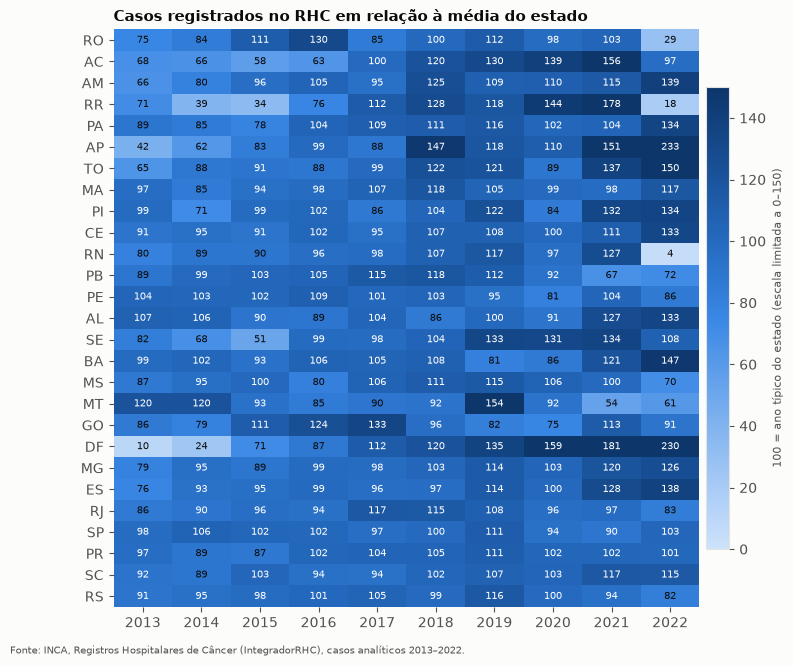

In [3]:
rhc = base.rhc()
por_uf_ano = rhc.pivot_table(index="uf_res", columns="ano_consulta", values="idade", aggfunc="size")
indice = por_uf_ano.div(por_uf_ano.loc[:, 2013:2021].mean(axis=1), axis=0).mul(100)
ordem = [s for r in c.REGIOES for s in c.SIGLAS_UF if c.SIGLA_PARA_REGIAO[s] == r]
fig, ax = g.calor(indice.reindex(ordem), "Casos registrados no RHC em relação à média do estado",
                  "100 = ano típico do estado (escala limitada a 0–150)", figsize=(9, 7.5), vmin=0, vmax=150)
g.salvar(fig, "01_cobertura_rhc_uf_ano", FONTE_RHC)
plt.show()

A maior parte dos estados oscila entre 80 e 120, o que é esperado. As células muito claras indicam anos em que faltam hospitais: em 2022, o Rio Grande do Norte registra só 4% de um ano típico, Roraima 18% e Rondônia 29%. Ou seja, os principais hospitais desses estados ainda não enviaram os dados daquele ano. As células muito escuras indicam o contrário, hospitais que passaram a enviar dados ao longo do período, como no Distrito Federal e no Amapá. Por isso, a evolução de um estado ao longo do tempo no RHC mistura mudanças reais com mudanças de cobertura.

Para análises por estado, convém olhar esta figura antes de interpretar um valor isolado. Para análises por região, somando dez anos, essas lacunas pesam pouco.

## Quanta informação está faltando

Algumas variáveis vêm frequentemente em branco ou como "sem informação". A tabela mostra a porcentagem de casos sem informação em cada variável do RHC, por região.

In [4]:
faltantes = pd.DataFrame({
    "Raça/cor": rhc.raca_cor.eq(c.SEM_INFO),
    "Escolaridade": rhc.escolaridade.eq(c.SEM_INFO),
    "Estado conjugal": rhc.estado_conjugal.eq(c.SEM_INFO),
    "Estádio": rhc.estadio.isna(),
    "Data do diagnóstico": rhc.data_diagnostico.isna(),
    "Data do tratamento": rhc.data_tratamento.isna(),
    "Município de residência": rhc.mun_res.isna(),
}).groupby(rhc.regiao_res).mean().mul(100).round(1).reindex(c.REGIOES)
base.salvar_tabela(faltantes, "01_rhc_percentual_sem_informacao", index=True)
faltantes

,Raça/cor,Escolaridade,Estado conjugal,Estádio,Data do diagnóstico,Data do tratamento,Município de residência
regiao_res,,,,,,,
Norte,18.5,12.9,11.4,38.8,0.3,2.3,0.0
Nordeste,8.4,23.7,10.3,31.2,1.0,3.8,0.0
Centro-Oeste,31.1,56.8,35.7,35.8,1.0,3.6,0.0
Sudeste,57.2,22.1,56.8,13.4,0.3,2.2,0.0
Sul,2.8,12.1,23.2,30.5,5.2,7.0,0.0


Três pontos merecem atenção no texto do TCC. Raça/cor está sem informação em mais da metade dos casos do Sudeste, porque a base do estado de São Paulo, que é a maior do país, quase não preenche esse campo. Por isso, as comparações por raça/cor são feitas também sem São Paulo. Escolaridade falta em mais da metade dos casos do Centro-Oeste. E o estádio está ausente em cerca de um terço dos casos fora do Sudeste, o que obriga a calcular a proporção de estádio avançado apenas entre os casos com estádio conhecido.

Nenhuma dessas lacunas invalida a análise, mas todas precisam ser declaradas. Os percentuais de informação faltante acompanham cada resultado nos cadernos seguintes.

## Um problema encontrado no download do RHC

O site do INCA oferece duas opções de download nacional: "todos os estados exceto São Paulo" e "todos os estados, inclusive São Paulo". A primeira opção vem com cerca de metade das linhas repetidas, idênticas em todos os 46 campos. Baixamos o mesmo arquivo duas vezes e a repetição era sempre a mesma, então não se trata de erro de transmissão, e sim de um defeito na exportação do site.

A segunda opção contém todos os registros da primeira, mais os de São Paulo, e tem menos de 0,5% de linhas repetidas. Usamos essa segunda opção e removemos as linhas exatamente iguais. Como seria praticamente impossível duas pacientes diferentes coincidirem em todos os campos, inclusive datas e hospital, essa remoção é segura. O código está em `src/mama/fontes/rhc.py`.

## Uma checagem externa

Uma forma simples de confirmar que a leitura dos arquivos está correta é comparar um número com um valor publicado oficialmente. O INCA informa 18.139 óbitos por câncer de mama em mulheres no Brasil em 2021. O caderno 11 reproduz exatamente esse número a partir do SIM.

## Resumo das decisões

O RHC é usado de 2013 a 2022, apenas com casos analíticos e com residência conhecida, o que resulta em pouco mais de 350 mil mulheres. O Painel é usado de 2013 a 2024, apenas para câncer invasivo (CID C50). Percentuais de estádio avançado são calculados entre os casos com estádio conhecido. Comparações por raça/cor são mostradas com e sem São Paulo. Cada figura informa a fonte e o período logo abaixo.